In [10]:
# Setup Python

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
pd.set_option('display.max_columns', 30)
plt.rcParams.update({
    'figure.figsize': (10, 4.5),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
})

OUTPUT_DIR = Path('output')
FIG_DIR = OUTPUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

def rp(x):
    return 'Rp' + f'{x:,.0f}'.replace(',', '.')

In [11]:
# Data synthetic Retail For Portofolio

def generate_retail_data(n_orders=6000, seed=42):
    rng = np.random.default_rng(seed)

    # ---- master SKU: kategori -> (harga_min, harga_max, rasio HPP)
    cat_cfg = {
        'Grocery': (8_000, 60_000, 0.78),
        'Beverage': (5_000, 35_000, 0.72),
        'Personal Care': (12_000, 90_000, 0.68),
        'Household': (10_000, 120_000, 0.70),
        'Snacks': (3_000, 25_000, 0.75),
        'Fresh Food': (7_000, 70_000, 0.80),
    }
    cats = list(cat_cfg)
    sku_records = []
    for i in range(1, 121):
        cat = cats[(i - 1) % len(cats)]
        lo, hi, ratio = cat_cfg[cat]
        price = round(rng.uniform(lo, hi) / 500) * 500
        cost = round(price * ratio * rng.uniform(0.95, 1.05) / 100) * 100
        sku_records.append({
            'SKU': f'SKU{i:03d}', 'ProductName': f'{cat} Item {i:03d}',
            'Category': cat, 'UnitPrice': float(price), 'UnitCost': float(cost),
        })

    # sedikit SKU sangat laku (pola Pareto)
    popularity = rng.pareto(1.2, len(sku_records)) + 1
    popularity = popularity / popularity.sum()

    # ---- tanggal order: tren naik + musiman + akhir pekan lebih ramai
    days = pd.date_range('2024-01-01', '2025-12-31', freq='D')
    t = np.arange(len(days))
    weight = ((1 + 0.5 * t / len(days))
              * (1 + 0.15 * np.sin(2 * np.pi * np.asarray(days.dayofyear) / 365))
              * np.where(np.asarray(days.dayofweek) >= 5, 1.3, 1.0))
    weight = weight / weight.sum()
    order_days = rng.choice(days.values, size=n_orders, p=weight)

    stores = ['JKT-01', 'JKT-02', 'BDG-01', 'SBY-01', 'TGR-01']
    store_p = [0.30, 0.25, 0.15, 0.15, 0.15]

    rows = []
    for n, day in enumerate(order_days, start=1):
        invoice = f'INV{n:06d}'
        ts = pd.Timestamp(day) + pd.Timedelta(minutes=int(rng.integers(8 * 60, 22 * 60)))
        store = str(rng.choice(stores, p=store_p))
        customer = f'C{rng.integers(1, 1501):04d}'
        if rng.random() < 0.08:
            customer = None
        n_items = int(np.clip(rng.poisson(2.5) + 1, 1, 10))
        picks = rng.choice(len(sku_records), size=n_items, replace=False, p=popularity)
        for idx in picks:
            s = sku_records[int(idx)]
            qty = int(rng.choice([1, 1, 1, 2, 2, 3, 5]))
            base = {'StoreID': store, 'CustomerID': customer, 'SKU': s['SKU'],
                    'ProductName': s['ProductName'], 'Category': s['Category'],
                    'UnitPrice': s['UnitPrice'], 'UnitCost': s['UnitCost']}
            rows.append({**base, 'InvoiceNo': invoice, 'InvoiceDate': ts, 'Quantity': qty})
            if rng.random() < 0.012:  # retur
                rows.append({**base, 'InvoiceNo': 'C' + invoice,
                             'InvoiceDate': ts + pd.Timedelta(days=int(rng.integers(1, 6))),
                             'Quantity': -qty})

    df = pd.DataFrame(rows)

    # ---- sengaja dikotori
    dirty = rng.choice(df.index, size=int(len(df) * 0.03), replace=False)
    df.loc[dirty, 'Category'] = df.loc[dirty, 'Category'].str.upper().radd(' ')
    zero_price = rng.choice(df.index, size=40, replace=False)
    df.loc[zero_price, 'UnitPrice'] = 0.0
    dup = df.sample(frac=0.01, random_state=seed)
    df = pd.concat([df, dup]).sample(frac=1, random_state=seed).reset_index(drop=True)

    cols = ['InvoiceNo', 'InvoiceDate', 'StoreID', 'CustomerID', 'SKU', 'ProductName',
            'Category', 'Quantity', 'UnitPrice', 'UnitCost']
    return df[cols]


DATA_SOURCE = 'synthetic'

if DATA_SOURCE == 'synthetic':
    raw = generate_retail_data()
else:
    raw = pd.read_csv(DATA_SOURCE)

print(f'Baris: {len(raw):,} | Kolom: {raw.shape[1]}')
display(raw.head())
display(raw.isna().sum().to_frame('jumlah_kosong').T)

Baris: 21,552 | Kolom: 10


,InvoiceNo,InvoiceDate,StoreID,CustomerID,SKU,ProductName,Category,Quantity,UnitPrice,UnitCost
0,INV002425,2025-06-02 12:16:00,JKT-01,C0559,SKU084,Fresh Food Item 084,Fresh Food,3,"59,500.00","49,100.00"
1,INV004727,2024-12-06 19:37:00,JKT-02,C0450,SKU099,Personal Care Item 099,Personal Care,1,"59,000.00","41,600.00"
2,INV000912,2024-11-21 21:52:00,JKT-01,C1422,SKU057,Personal Care Item 057,Personal Care,2,"36,000.00","24,700.00"
3,INV004961,2025-04-27 18:36:00,JKT-02,C0480,SKU079,Grocery Item 079,Grocery,5,"22,500.00","17,800.00"
4,INV005997,2025-11-25 21:20:00,JKT-02,C0535,SKU007,Grocery Item 007,Grocery,2,"41,500.00","33,400.00"


,InvoiceNo,InvoiceDate,StoreID,CustomerID,SKU,ProductName,Category,Quantity,UnitPrice,UnitCost
jumlah_kosong,0,0,0,1716,0,0,0,0,0,0


In [17]:
# Data Cleaning (Log Kualitas Data)

def clean_retail_data(raw):
    df = raw.copy()
    log = []

    def step(name, before, after):
        log.append({'langkah': name, 'baris_sebelum': before, 'baris_sesudah': after, 'baris_terdampak': before - after})

    # Standarisasi teks
    fixed_cat = (df['Category'] != df['Category'].str.strip().str.title()).sum()
    for col in ['Category', 'StoreID', 'SKU']:
        df[col] = df[col].astype(str).str.strip()
    df['Category'] = df['Category'].str.title()
    df['StoreID'] = df['StoreID'].str.upper()
    log.append({'langkah': 'Standarisasi teks Category', 'baris_sebelum': len(df), 'baris_sesudah': len(df), 'baris_terdampak': int(fixed_cat)})

    # Tipe Data Tanggal
    n = len(df); df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
    df = df.dropna(subset=['InvoiceDate']); step('Tanggal tidak valid dibuang', n, len(df))

    # Duplikat
    n = len(df); df = df.drop_duplicates(); step('Duplikat dibuang', n, len(df))

    # Return Dipisah
    returns = df[df['Quantity'] < 0].copy()
    n = len(df); df = df[df['Quantity'] > 0]; step('Retur dipisahkan (Quantity < 0)', n, len(df))

    # Harga
    n = len(df); df = df[df['UnitPrice'] > 0]; step('Harga 0/negatif dibuang', n, len(df))

    # Customer
    missing_cust = int(df['CustomerID'].isna().sum())
    df['CustomerID'] = df['CustomerID'].fillna('GUEST')
    log.append({'langkah': "CustomerID kosong diisi 'GUEST'", 'baris_sebelum': len(df), 'baris_sesudah': len(df), 'baris_terdampak': missing_cust})

    # Kolom Turunan
    df['Revenue'] = df['Quantity'] * df['UnitPrice']
    df['COGS'] = df['Quantity'] * df['UnitCost']
    df['GrossProfit'] = df['Revenue'] - df['COGS']
    df['Month'] = df['InvoiceDate'].dt.to_period('M').dt.to_timestamp()

    sales = df.sort_values('InvoiceDate').reset_index(drop=True)

    # Validation
    assert sales['Revenue'].gt(0).all(), 'Ada revenue <= 0'
    assert sales['InvoiceNo'].notna().all(), 'Ada InvoiceNo kosong'
    assert not sales.duplicated().any(), 'Masih ada duplikat'
    assert sales['Category'].nunique() == 6, 'Kategori tidak konsisten'

    quality_log = pd.DataFrame(log)
    display(quality_log)
    print(f'Data bersih: {len(sales):,} baris | Retur terpisah: {len(returns):,} baris')
    
    return sales, returns, quality_log
    
sales, returns, quality_log = clean_retail_data(raw)

,langkah,baris_sebelum,baris_sesudah,baris_terdampak
0,Standarisasi teks Category,21552,21552,648
1,Tanggal tidak valid dibuang,21552,21552,0
2,Duplikat dibuang,21552,21339,213
3,Retur dipisahkan (Quantity < 0),21339,21090,249
4,Harga 0/negatif dibuang,21090,21050,40
5,CustomerID kosong diisi 'GUEST',21050,21050,1681


Data bersih: 21,050 baris | Retur terpisah: 249 baris


In [20]:
# Membuat KPI (Revenue, Gross Profit, Orders, Units

total_rev = sales['Revenue'].sum()
gross_profit = sales['GrossProfit'].sum()
n_orders = sales['InvoiceNo'].nunique()
units = sales['Quantity'].sum()
n_customers = sales.loc[sales['CustomerID'] != 'GUEST', 'CustomerID'].nunique()
return_value = (returns['Quantity'].abs() * returns['UnitPrice']).sum()

kpi = pd.DataFrame({
    'KPI': ['Total Revenue', 'Gross Profit', 'Gross Margin', 'Jumlah Order', 'AOV',
            'Basket Size', 'Pelanggan Unik', 'Return Rate'],
    'Nilai': [rp(total_rev), rp(gross_profit), f'{gross_profit / total_rev:.1%}', f'{n_orders:,}',
              rp(total_rev / n_orders), f'{units / n_orders:.2f} unit/order', f'{n_customers:,}',
              f'{return_value / (total_rev + return_value):.2%}']
})

kpi

,KPI,Nilai
0,Total Revenue,Rp1.591.219.500
1,Gross Profit,Rp416.064.200
2,Gross Margin,26.1%
3,Jumlah Order,"5,999"
4,AOV,Rp265.247
5,Basket Size,7.53 unit/order
6,Pelanggan Unik,"1,474"
7,Return Rate,1.08%


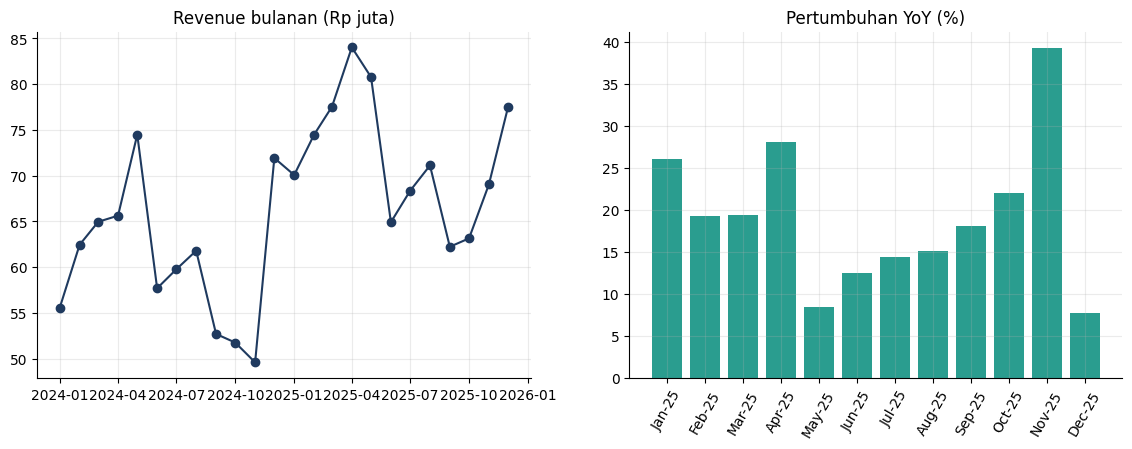

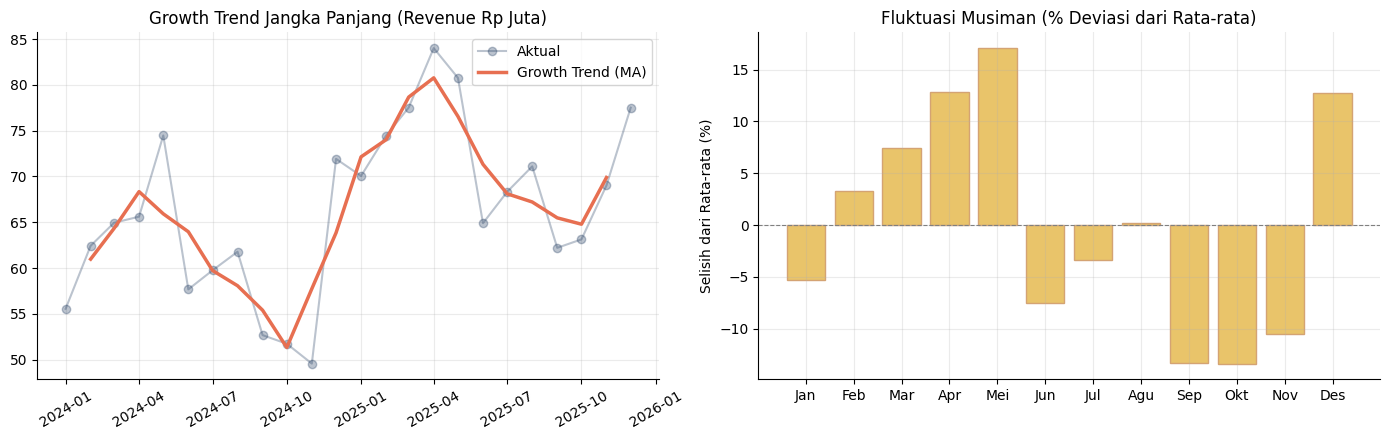

,Month,Revenue,GrossProfit,Orders,GM_pct,MoM_pct,YoY_pct,Trend,Month_Num
18,2025-07-01,"68,333,000.00","17,721,600.00",268,0.26,0.05,0.14,"68,113,500.00",7
19,2025-08-01,"71,105,500.00","18,369,000.00",250,0.26,0.04,0.15,"67,217,500.00",8
20,2025-09-01,"62,214,000.00","16,239,300.00",249,0.26,-0.13,0.18,"65,484,666.67",9
21,2025-10-01,"63,134,500.00","16,338,100.00",240,0.26,0.01,0.22,"64,791,666.67",10
22,2025-11-01,"69,026,500.00","18,217,500.00",261,0.26,0.09,0.39,"69,891,500.00",11
23,2025-12-01,"77,513,500.00","20,037,700.00",282,0.26,0.12,0.08,NaN,12


In [26]:
# Monthly Trend

monthly = (sales.groupby('Month')
           .agg(Revenue=('Revenue', 'sum'), GrossProfit=('GrossProfit', 'sum'),
                Orders=('InvoiceNo', 'nunique'))
           .reset_index())
monthly['GM_pct'] = monthly['GrossProfit'] / monthly['Revenue']
monthly['MoM_pct'] = monthly['Revenue'].pct_change()
monthly['YoY_pct'] = monthly['Revenue'].pct_change(12)
monthly['Trend'] = monthly['Revenue'].rolling(window=3, center=True).mean()
monthly['Month_Num'] = monthly['Month'].dt.month
seasonal_idx = monthly.groupby('Month_Num')['Revenue'].mean() / monthly['Revenue'].mean()
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

# Revenue Bulanan & Pertumbuhan YoY
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(monthly['Month'], monthly['Revenue'] / 1e6, marker='o', color='#1F3A5F')
axes[0].set_title('Revenue bulanan (Rp juta)')
yoy = monthly.dropna(subset=['YoY_pct'])
axes[1].bar(yoy['Month'].dt.strftime('%b-%y'), yoy['YoY_pct'] * 100, color='#2A9D8F')
axes[1].set_title('Pertumbuhan YoY (%)')
axes[1].tick_params(axis='x', rotation=60)

# Growth Trend & Fluktuasi Musiman
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 4.5))
axes2[0].plot(monthly['Month'], monthly['Revenue'] / 1e6, marker='o', color='#1F3A5F', alpha=0.3, label='Aktual')
axes2[0].plot(monthly['Month'], monthly['Trend'] / 1e6, color='#E76F51', linewidth=2.5, label='Growth Trend (MA)')
axes2[0].set_title('Growth Trend Jangka Panjang (Revenue Rp Juta)')
axes2[0].legend(frameon=True)
axes2[0].tick_params(axis='x', rotation=30)
axes2[1].bar(month_labels[:len(seasonal_idx)], (seasonal_idx.values - 1) * 100, color='#E9C46A', edgecolor='#D4A373')
axes2[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes2[1].set_title('Fluktuasi Musiman (% Deviasi dari Rata-rata)')
axes2[1].set_ylabel('Selisih dari Rata-rata (%)')

plt.tight_layout()
fig.savefig(FIG_DIR / '01_trend.png', dpi=150)
fig2.savefig(FIG_DIR / '02_seasonality_trend.png', dpi=150)
plt.show()

monthly.tail(6)

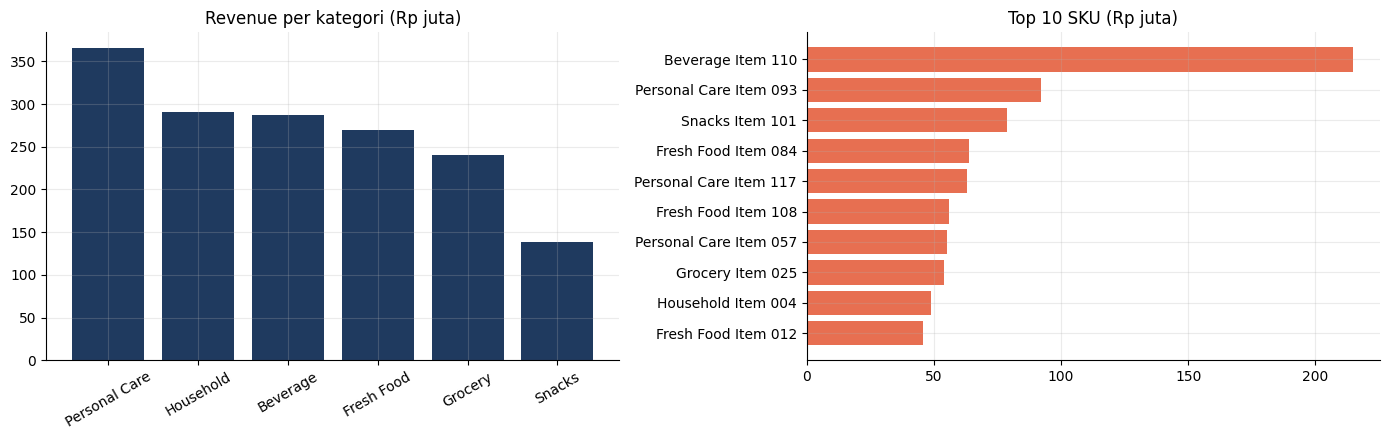

,Revenue,GrossProfit,Orders,GM_pct,Share
Category,,,,,
Personal Care,"365,733,000.00","114,140,200.00",2658,0.31,0.23
Household,"290,321,500.00","83,629,900.00",1795,0.29,0.18
Beverage,"286,659,500.00","82,483,600.00",4051,0.29,0.18
Fresh Food,"269,787,000.00","49,871,400.00",2295,0.18,0.17
Grocery,"240,631,000.00","54,424,100.00",2634,0.23,0.15
Snacks,"138,087,500.00","31,515,000.00",3166,0.23,0.09


In [27]:
# Produk

cat = (sales.groupby('Category')
       .agg(Revenue=('Revenue', 'sum'), GrossProfit=('GrossProfit', 'sum'),
            Orders=('InvoiceNo', 'nunique'))
       .assign(GM_pct=lambda d: d['GrossProfit'] / d['Revenue'],
               Share=lambda d: d['Revenue'] / d['Revenue'].sum())
       .sort_values('Revenue', ascending=False))

top_sku = (sales.groupby(['SKU', 'ProductName', 'Category'])
           .agg(Revenue=('Revenue', 'sum'), Units=('Quantity', 'sum'), GrossProfit=('GrossProfit', 'sum'))
           .reset_index()
           .sort_values('Revenue', ascending=False)
           .reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(cat.index, cat['Revenue'] / 1e6, color='#1F3A5F')
axes[0].set_title('Revenue per kategori (Rp juta)')
axes[0].tick_params(axis='x', rotation=30)
t10 = top_sku.head(10).iloc[::-1]
axes[1].barh(t10['ProductName'], t10['Revenue'] / 1e6, color='#E76F51')
axes[1].set_title('Top 10 SKU (Rp juta)')
plt.tight_layout()
fig.savefig(FIG_DIR / '02_category_top_sku.png', dpi=150)
plt.show()

display(cat)

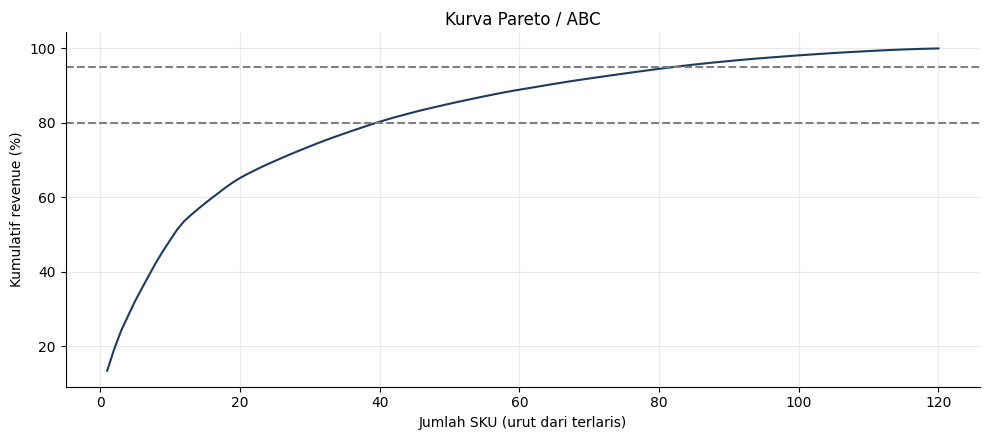

,Jumlah_SKU,Revenue,Share_SKU,Share_Revenue
ABC,,,,
A,40,"1,277,813,000.00",0.33,0.80
B,42,"233,958,500.00",0.35,0.15
C,38,"79,448,000.00",0.32,0.05


In [28]:
abc = top_sku.copy()
total = abc['Revenue'].sum()
abc['CumShare'] = abc['Revenue'].cumsum() / total
abc['PrevShare'] = abc['CumShare'] - abc['Revenue'] / total   # SKU yang melewati 80% tetap kelas A
abc['ABC'] = np.select([abc['PrevShare'] < 0.80, abc['PrevShare'] < 0.95], ['A', 'B'], default='C')

abc_summary = (abc.groupby('ABC')
               .agg(Jumlah_SKU=('SKU', 'count'), Revenue=('Revenue', 'sum'))
               .assign(Share_SKU=lambda d: d['Jumlah_SKU'] / d['Jumlah_SKU'].sum(),
                       Share_Revenue=lambda d: d['Revenue'] / d['Revenue'].sum()))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(np.arange(1, len(abc) + 1), abc['CumShare'] * 100, color='#1F3A5F')
ax.axhline(80, ls='--', color='grey'); ax.axhline(95, ls='--', color='grey')
ax.set_xlabel('Jumlah SKU (urut dari terlaris)'); ax.set_ylabel('Kumulatif revenue (%)')
ax.set_title('Kurva Pareto / ABC')
plt.tight_layout()
fig.savefig(FIG_DIR / '03_abc.png', dpi=150)
plt.show()

abc_summary

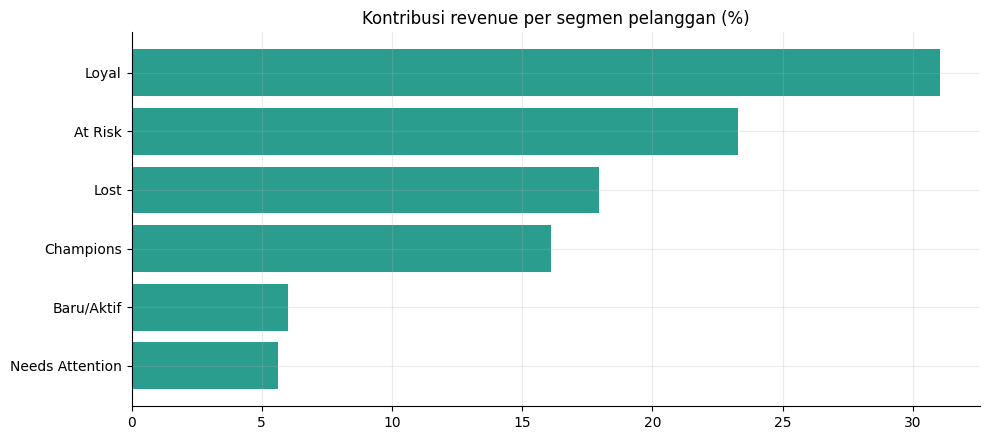

,Pelanggan,Revenue,Rata2_Recency,Rata2_Frekuensi,Share_Revenue
Segment,,,,,
Loyal,344,"455,279,500.00",69.08,5.05,0.31
At Risk,260,"341,566,500.00",232.63,4.90,0.23
Lost,477,"263,533,500.00",325.09,2.14,0.18
Champions,133,"236,519,500.00",22.71,6.32,0.16
Baru/Aktif,132,"87,893,500.00",24.46,2.50,0.06
Needs Attention,128,"82,453,500.00",87.31,2.45,0.06


In [29]:
# Segmentasi Pealnggan

known = sales[sales['CustomerID'] != 'GUEST']
snapshot = known['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)

rfm = known.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda s: (snapshot - s.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
)
# rank(method='first') mencegah error qcut karena nilai kembar
rfm['R'] = pd.qcut(rfm['Recency'].rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['M'] = pd.qcut(rfm['Monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)


def segment(r):
    if r['R'] >= 4 and r['F'] >= 4:
        return 'Champions'
    if r['R'] >= 3 and r['F'] >= 3:
        return 'Loyal'
    if r['R'] >= 4:
        return 'Baru/Aktif'
    if r['R'] <= 2 and r['F'] >= 3:
        return 'At Risk'
    if r['R'] <= 2:
        return 'Lost'
    return 'Needs Attention'


rfm['Segment'] = rfm.apply(segment, axis=1)

seg = (rfm.groupby('Segment')
       .agg(Pelanggan=('R', 'size'), Revenue=('Monetary', 'sum'),
            Rata2_Recency=('Recency', 'mean'), Rata2_Frekuensi=('Frequency', 'mean'))
       .assign(Share_Revenue=lambda d: d['Revenue'] / d['Revenue'].sum())
       .sort_values('Revenue', ascending=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(seg.index[::-1], seg['Share_Revenue'][::-1] * 100, color='#2A9D8F')
ax.set_title('Kontribusi revenue per segmen pelanggan (%)')
plt.tight_layout()
fig.savefig(FIG_DIR / '04_rfm.png', dpi=150)
plt.show()

seg

In [30]:
# Ekspor Tableau

sales.to_csv(OUTPUT_DIR / 'tableau_sales_clean.csv', index=False)
monthly.to_csv(OUTPUT_DIR / 'tableau_monthly.csv', index=False)
rfm.reset_index().to_csv(OUTPUT_DIR / 'tableau_rfm.csv', index=False)
print(sorted(p.name for p in OUTPUT_DIR.iterdir() if p.is_file()))

['tableau_monthly.csv', 'tableau_rfm.csv', 'tableau_sales_clean.csv']


In [34]:
# optimation Excel (From AI)

!pip install xlsxwriter
!pip install openpyxl

report_path = OUTPUT_DIR / 'retail_report.xlsx'

monthly_x = monthly[['Month', 'Revenue', 'GrossProfit', 'Orders']].copy()
monthly_x['Month'] = monthly_x['Month'].dt.strftime('%Y-%m')
n_m = len(monthly_x)

with pd.ExcelWriter(report_path, engine='xlsxwriter') as writer:
    wb = writer.book
    f_pct = wb.add_format({'num_format': '0.0%'})
    f_num = wb.add_format({'num_format': '#,##0'})
    f_head = wb.add_format({'bold': True, 'bg_color': '#1F3A5F', 'font_color': 'white'})

    # Sheet 1: ringkasan KPI
    kpi.to_excel(writer, sheet_name='Summary', index=False)

    # Sheet 2: tren bulanan + rumus Excel asli
    monthly_x.to_excel(writer, sheet_name='Monthly', index=False)
    ws = writer.sheets['Monthly']
    ws.write(0, 4, 'GM_pct', f_head)
    ws.write(0, 5, 'MoM_pct', f_head)
    for i in range(n_m):
        r = i + 2                                   # nomor baris Excel (header = baris 1)
        ws.write_formula(i + 1, 4, f'=C{r}/B{r}', f_pct, float(monthly['GM_pct'].iloc[i]))
        if i == 0:
            ws.write_blank(i + 1, 5, None, f_pct)
        else:
            ws.write_formula(i + 1, 5, f'=B{r}/B{r - 1}-1', f_pct, float(monthly['MoM_pct'].iloc[i]))
    ws.set_column('B:C', 16, f_num)
    ws.conditional_format(1, 1, n_m, 1, {'type': 'data_bar', 'bar_color': '#9DB4D0'})
    ws.conditional_format(1, 4, n_m, 4, {'type': '3_color_scale'})
    chart = wb.add_chart({'type': 'line'})
    chart.add_series({'name': 'Revenue', 'categories': ['Monthly', 1, 0, n_m, 0],
                      'values': ['Monthly', 1, 1, n_m, 1]})
    chart.set_title({'name': 'Revenue bulanan'})
    chart.set_legend({'none': True})
    ws.insert_chart('H2', chart)

    # Sheet lain
    cat.reset_index().to_excel(writer, sheet_name='Category', index=False)
    top_sku.head(20).to_excel(writer, sheet_name='Top_SKU', index=False)
    abc[['SKU', 'ProductName', 'Category', 'Revenue', 'CumShare', 'ABC']].to_excel(
        writer, sheet_name='ABC', index=False)
    seg.reset_index().to_excel(writer, sheet_name='RFM_Segments', index=False)
    quality_log.to_excel(writer, sheet_name='Data_Quality', index=False)

    for name, sheet in writer.sheets.items():
        sheet.freeze_panes(1, 0)
        if hasattr(sheet, 'autofit'):
            sheet.autofit()

# Verifikasi: rumus benar-benar tersimpan sebagai rumus
from openpyxl import load_workbook
chk = load_workbook(report_path)
assert str(chk['Monthly']['E2'].value).startswith('='), 'Rumus tidak tersimpan'
print('Laporan Excel dibuat:', report_path, '| sheet:', chk.sheetnames)


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Laporan Excel dibuat: output/retail_report.xlsx | sheet: ['Summary', 'Monthly', 'Category', 'Top_SKU', 'ABC', 'RFM_Segments', 'Data_Quality']
